# Radar Detection using GNN

In [1]:
#import libraries
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split


## load a dataframe form the image dataset 

In [2]:
from pathlib import Path
root = Path("dataset")
df = pd.read_csv("dataset/metadata.csv")
df.head()


,idx,class,radarType,radarIndex,filename,SNR_dB,SIR_dB,SINR_dB,UE1_x,UE1_y,...,UE3_z,gNB_x,gNB_y,gNB_z,radar_x,radar_y,radar_z,pathLossModel,numUE,numRx
0,1,5G_only,NaN,0,5G_only_None_SNR+2p4_SIRNA_example_0001.png,2.4283,NaN,2.4283,955.2473,979.3998,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4
1,2,5G_only,NaN,0,5G_only_None_SNR+17p3_SIRNA_example_0002.png,17.2732,NaN,17.2732,486.6093,1023.7820,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,LogDistance,3,4
2,3,5G_only,NaN,0,5G_only_None_SNR+9p5_SIRNA_example_0003.png,9.4714,NaN,9.4714,591.0226,-891.5218,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4
3,4,5G_only,NaN,0,5G_only_None_SNR+17p1_SIRNA_example_0004.png,17.1139,NaN,17.1139,-325.7365,-180.3630,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4
4,5,5G_only,NaN,0,5G_only_None_SNR+11p6_SIRNA_example_0005.png,11.6430,NaN,11.6430,-44.3829,-150.8747,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,FSPL,3,4


In [3]:
df['SNR_dB']

0        2.4283
1       17.2732
2        9.4714
3       17.1139
4       11.6430
         ...   
4995    22.0687
4996     1.9307
4997     9.6735
4998    23.1885
4999    22.3980
Name: SNR_dB, Length: 5000, dtype: float64

In [4]:
# df.isna()
# import numpy as np

df.loc[df['SIR_dB'].isna(), 'SIR_dB'] = 0

In [5]:
type(df)

pandas.DataFrame

In [6]:
#create dataset with column that includes actual path to images 
def make_path(row):
    return root / row["class"] / row["filename"]

df["path"] = df.apply(make_path, axis=1)
#drop the filename column 
df1 = df.drop(columns="filename")


In [7]:
df1.describe()

,idx,radarIndex,SNR_dB,SIR_dB,SINR_dB,UE1_x,UE1_y,UE1_z,UE2_x,UE2_y,...,UE3_y,UE3_z,gNB_x,gNB_y,gNB_z,radar_x,radar_y,radar_z,numUE,numRx
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,...,5000.000000,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
mean,2500.500000,1.257000,12.517156,-0.002380,5.810431,-7.967611,6.456715,0.0,4.113363,-3.242548,...,2.217952,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0
std,1443.520003,1.485864,7.148202,4.172353,9.219744,627.800429,638.355877,0.0,636.022066,628.220098,...,633.231657,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,1.000000,0.000000,0.016300,-9.987200,-10.283000,-1488.475400,-1483.805200,0.0,-1493.178400,-1487.057000,...,-1493.209900,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0
25%,1250.750000,0.000000,6.374125,0.000000,-0.896125,-430.263025,-427.537150,0.0,-427.560125,-425.210275,...,-420.838125,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0
50%,2500.500000,0.500000,12.581250,0.000000,4.643450,-4.332800,7.337550,0.0,-2.313700,3.511300,...,2.571550,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0
75%,3750.250000,2.000000,18.585175,0.001800,12.850825,408.223550,439.020850,0.0,437.523625,406.994925,...,410.380050,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0
max,5000.000000,4.000000,24.989700,9.991100,24.985300,1497.176600,1493.443600,0.0,1489.627000,1472.320000,...,1494.943900,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0


In [8]:
df1.head()

,idx,class,radarType,radarIndex,SNR_dB,SIR_dB,SINR_dB,UE1_x,UE1_y,UE1_z,...,gNB_x,gNB_y,gNB_z,radar_x,radar_y,radar_z,pathLossModel,numUE,numRx,path
0,1,5G_only,NaN,0,2.4283,0.0,2.4283,955.2473,979.3998,0.0,...,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+2p4_SIRNA_exa...
1,2,5G_only,NaN,0,17.2732,0.0,17.2732,486.6093,1023.7820,0.0,...,0.0,0.0,0.0,3000.0,400.0,0.0,LogDistance,3,4,dataset/5G_only/5G_only_None_SNR+17p3_SIRNA_ex...
2,3,5G_only,NaN,0,9.4714,0.0,9.4714,591.0226,-891.5218,0.0,...,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+9p5_SIRNA_exa...
3,4,5G_only,NaN,0,17.1139,0.0,17.1139,-325.7365,-180.3630,0.0,...,0.0,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+17p1_SIRNA_ex...
4,5,5G_only,NaN,0,11.6430,0.0,11.6430,-44.3829,-150.8747,0.0,...,0.0,0.0,0.0,3000.0,400.0,0.0,FSPL,3,4,dataset/5G_only/5G_only_None_SNR+11p6_SIRNA_ex...


## Exploratory Data Analysis


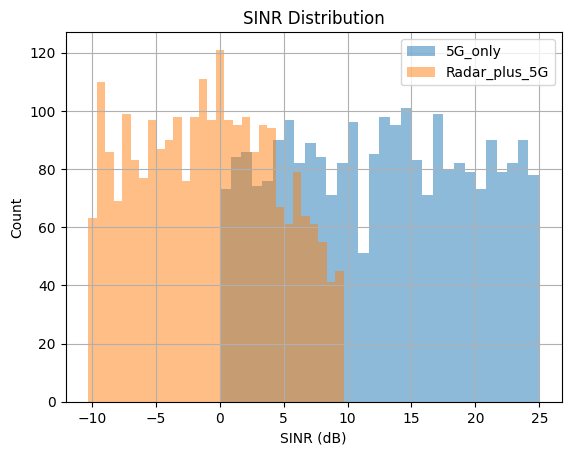

In [9]:
#check the balance between classes 

df1["class"].value_counts()
#encode the class column 
label_map = {"5G_only":0, "Radar_plus_5G":1 }
df["y"] = df["class"].map(label_map).astype(int)
#check balance in classes between the SNR
plt.figure()

for cls in df["class"].unique():
    df[df["class"] == cls]["SINR_dB"].hist(
        alpha=0.5,
        bins=30,
        label=cls
    )

plt.legend()
plt.title("SINR Distribution")
plt.xlabel("SINR (dB)")
plt.ylabel("Count")
plt.show()

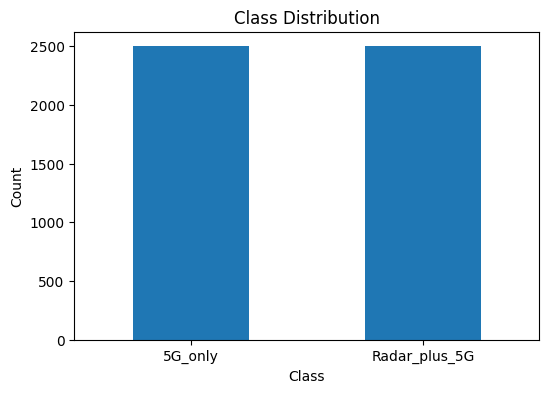

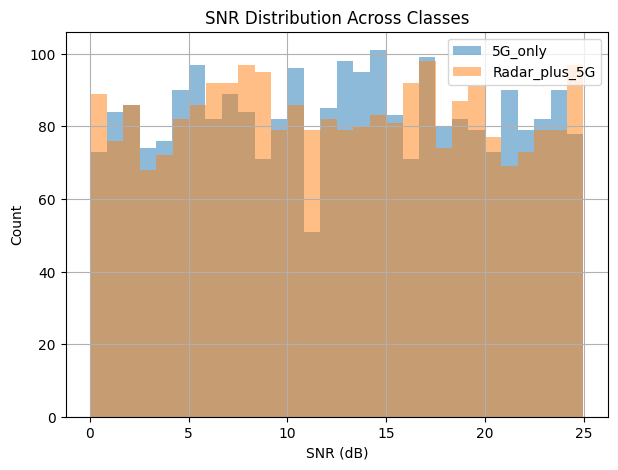

In [10]:
import matplotlib.pyplot as plt

# Encode classes
label_map = {
    "5G_only": 0,
    "Radar_plus_5G": 1
}

df["y"] = df["class"].map(label_map).astype(int)

# ---------------------------------------------------
# Class Distribution
# ---------------------------------------------------

plt.figure(figsize=(6,4))

df["class"].value_counts().plot(
    kind='bar'
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")

plt.xticks(rotation=0)

plt.show()


# ---------------------------------------------------
# SNR Distribution Per Class
# ---------------------------------------------------

plt.figure(figsize=(7,5))

for cls in df["class"].unique():

    df[df["class"] == cls]["SNR_dB"].hist(
        alpha=0.5,
        bins=30,
        label=cls
    )

plt.legend()

plt.title("SNR Distribution Across Classes")

plt.xlabel("SNR (dB)")

plt.ylabel("Count")

plt.show()

In [11]:
df.describe()

,idx,radarIndex,SNR_dB,SIR_dB,SINR_dB,UE1_x,UE1_y,UE1_z,UE2_x,UE2_y,...,UE3_z,gNB_x,gNB_y,gNB_z,radar_x,radar_y,radar_z,numUE,numRx,y
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,...,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.00000
mean,2500.500000,1.257000,12.517156,-0.002380,5.810431,-7.967611,6.456715,0.0,4.113363,-3.242548,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,0.50000
std,1443.520003,1.485864,7.148202,4.172353,9.219744,627.800429,638.355877,0.0,636.022066,628.220098,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.50005
min,1.000000,0.000000,0.016300,-9.987200,-10.283000,-1488.475400,-1483.805200,0.0,-1493.178400,-1487.057000,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,0.00000
25%,1250.750000,0.000000,6.374125,0.000000,-0.896125,-430.263025,-427.537150,0.0,-427.560125,-425.210275,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,0.00000
50%,2500.500000,0.500000,12.581250,0.000000,4.643450,-4.332800,7.337550,0.0,-2.313700,3.511300,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,0.50000
75%,3750.250000,2.000000,18.585175,0.001800,12.850825,408.223550,439.020850,0.0,437.523625,406.994925,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,1.00000
max,5000.000000,4.000000,24.989700,9.991100,24.985300,1497.176600,1493.443600,0.0,1489.627000,1472.320000,...,0.0,0.0,0.0,0.0,3000.0,400.0,0.0,3.0,4.0,1.00000


In [12]:
#fill the NAN SIR values with 0.0
df['SIR_dB'] = df.SIR_dB.fillna(0.0)

#shuffle the data set 
df = df.sample(frac=1, random_state=42)

In [13]:
# df = df.drop(columns='idx')
# df = df.drop(columns="class1")

In [14]:
df

,idx,class,radarType,radarIndex,filename,SNR_dB,SIR_dB,SINR_dB,UE1_x,UE1_y,...,gNB_y,gNB_z,radar_x,radar_y,radar_z,pathLossModel,numUE,numRx,path,y
1501,1502,5G_only,NaN,0,5G_only_None_SNR+3p9_SIRNA_example_1502.png,3.8738,0.0000,3.8738,-591.4842,193.9515,...,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+3p9_SIRNA_exa...,0
2586,2587,Radar_plus_5G,FMCW,2,Radar_plus_5G_FMCW_SNR+22p2_SIR-3p8_example_00...,22.1806,-3.7797,-3.7907,-183.3942,-115.2845,...,0.0,0.0,3000.0,400.0,0.0,FSPL,3,4,dataset/Radar_plus_5G/Radar_plus_5G_FMCW_SNR+2...,1
2653,2654,Radar_plus_5G,LFM,1,Radar_plus_5G_LFM_SNR+14p0_SIR+9p9_example_015...,13.9581,9.8502,8.4253,1011.7674,689.2838,...,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/Radar_plus_5G/Radar_plus_5G_LFM_SNR+14...,1
1055,1056,5G_only,NaN,0,5G_only_None_SNR+5p3_SIRNA_example_1056.png,5.3200,0.0000,5.3200,-619.0411,1220.1791,...,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+5p3_SIRNA_exa...,0
705,706,5G_only,NaN,0,5G_only_None_SNR+17p8_SIRNA_example_0706.png,17.8463,0.0000,17.8463,1004.6627,-60.5256,...,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+17p8_SIRNA_ex...,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,4427,Radar_plus_5G,NLFM,3,Radar_plus_5G_NLFM_SNR+1p9_SIR+4p9_example_192...,1.9284,4.9207,0.1615,718.2416,-254.7124,...,0.0,0.0,3000.0,400.0,0.0,LogDistance,3,4,dataset/Radar_plus_5G/Radar_plus_5G_NLFM_SNR+1...,1
466,467,5G_only,NaN,0,5G_only_None_SNR+23p3_SIRNA_example_0467.png,23.3472,0.0000,23.3472,261.4319,-1237.3495,...,0.0,0.0,3000.0,400.0,0.0,UMa,3,4,dataset/5G_only/5G_only_None_SNR+23p3_SIRNA_ex...,0
3092,3093,Radar_plus_5G,P4,4,Radar_plus_5G_P4_SNR+10p5_SIR+5p4_example_0593...,10.5420,5.3640,4.2128,168.3872,610.8393,...,0.0,0.0,3000.0,400.0,0.0,LogDistance,3,4,dataset/Radar_plus_5G/Radar_plus_5G_P4_SNR+10p...,1
3772,3773,Radar_plus_5G,LFM,1,Radar_plus_5G_LFM_SNR+14p1_SIR-1p6_example_127...,14.0862,-1.5584,-1.6752,-211.5863,-280.2780,...,0.0,0.0,3000.0,400.0,0.0,LogDistance,3,4,dataset/Radar_plus_5G/Radar_plus_5G_LFM_SNR+14...,1


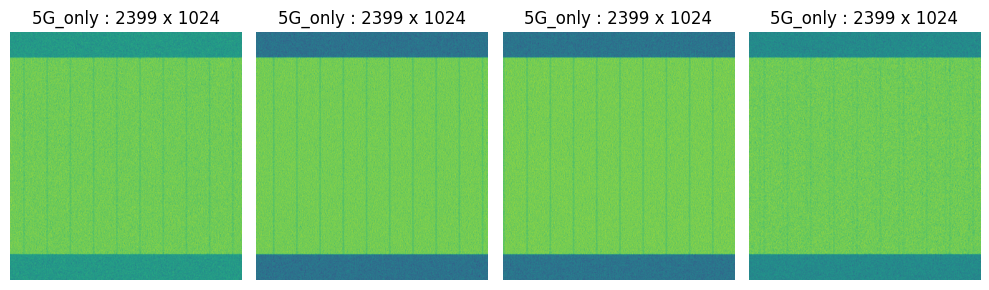

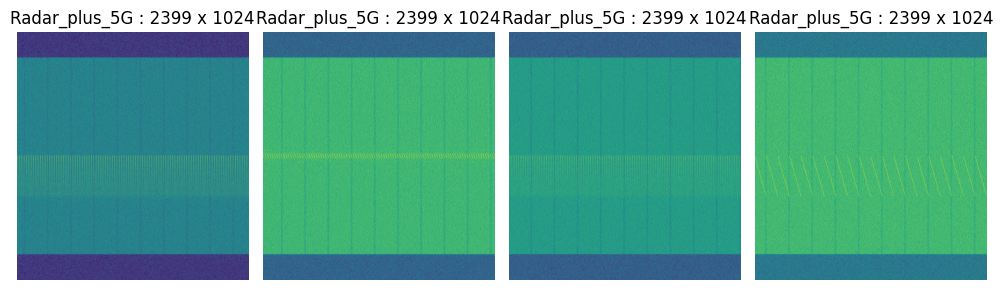

In [15]:
from PIL import Image
import random

def show_random(cls=None, k=4):
    sub = df if cls is None else df[df["class"] == cls]
    sample = sub.sample(k, random_state=random.randint(0, 10_000))
    plt.figure(figsize=(10, 3))
    for i, (_, row) in enumerate(sample.iterrows()):
        img = Image.open(row["path"]).convert("L")
        plt.subplot(1, k, i+1)
        plt.imshow(np.array(img), aspect="auto")
        plt.title(f"{row['class']} : {img.size[0]} x {img.size[1]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_random("5G_only", 4)
show_random("Radar_plus_5G", 4)


In [16]:
sizes = df["path"].apply(lambda p: Image.open(p).size)
df["W"] = sizes.apply(lambda s: s[0])
df["H"] = sizes.apply(lambda s: s[1])
print(df[["W","H"]].describe())


            W       H
count  5000.0  5000.0
mean   2399.0  1024.0
std       0.0     0.0
min    2399.0  1024.0
25%    2399.0  1024.0
50%    2399.0  1024.0
75%    2399.0  1024.0
max    2399.0  1024.0


In [17]:

train_df, test_df = train_test_split(df, test_size=0.15, stratify=df["y"], random_state=42)
train_df, val_df  = train_test_split(train_df, test_size=0.15, stratify=train_df["y"], random_state=42)

print(len(train_df), len(val_df), len(test_df))
# print(len(train_df), len(test_df))


3612 638 750


## Load graph data set

In [18]:
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split
import graph_utils
import dataset_pyg
import importlib

importlib.reload(graph_utils)
importlib.reload(dataset_pyg)

import dataset_pyg as dt

train_set = dt.SpectrogramGraphDataset(train_df)
val_set   = dt.SpectrogramGraphDataset(val_df)
test_set  = dt.SpectrogramGraphDataset(test_df)

train_loader = DataLoader(train_set, batch_size=124, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=124)
test_loader  = DataLoader(test_set, batch_size=124)
# train_loader, test_loader = make_cross_eval_loaders(
#     df,
#     train_condition=(df["pathLossModel"] == "UMa"),
#     test_condition=(df["pathLossModel"] == "FSPL"),
#     batch_size=124,
#     patch_size=16
# )

/home/vmasc/Documents/ECE883_Digital_Image_processing/Final_project/gnn_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Crossevaluation experimental design

In [19]:
from sklearn.model_selection import train_test_split
from torch_geometric.loader import DataLoader


def make_cross_eval_loaders(
    development_df,
    test_df,
    batch_size=124,
    patch_size=16,
    val_size=0.15,
    random_state=42
):
    
    # --------------------------------------------------
    # 1. Make copies so original DataFrames are unchanged
    # --------------------------------------------------
    development_df = development_df.copy().reset_index(drop=True)
    test_df = test_df.copy().reset_index(drop=True)

    # --------------------------------------------------
    # 2. Split development pool into train + validation
    # --------------------------------------------------
    train_df, val_df = train_test_split(
        development_df,
        test_size=val_size,
        stratify=development_df["class"],
        random_state=random_state,
        shuffle=True
    )

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)

    # --------------------------------------------------
    # 3. Check the splits
    # --------------------------------------------------
    print("\nTRAIN")
    print("Size:", len(train_df))
    print(train_df["class"].value_counts())

    print("\nVALIDATION")
    print("Size:", len(val_df))
    print(val_df["class"].value_counts())

    print("\nTEST")
    print("Size:", len(test_df))
    print(test_df["class"].value_counts())

    # --------------------------------------------------
    # 4. Check SIR ranges for radar-positive samples
    # --------------------------------------------------
    print("\nRADAR SIR RANGES")

    train_radar = train_df[train_df["class"] == "Radar_plus_5G"]
    val_radar = val_df[val_df["class"] == "Radar_plus_5G"]
    test_radar = test_df[test_df["class"] == "Radar_plus_5G"]

    print(
        "Train radar SIR:",
        train_radar["SIR_dB"].min(),
        "to",
        train_radar["SIR_dB"].max()
    )

    print(
        "Validation radar SIR:",
        val_radar["SIR_dB"].min(),
        "to",
        val_radar["SIR_dB"].max()
    )

    print(
        "Test radar SIR:",
        test_radar["SIR_dB"].min(),
        "to",
        test_radar["SIR_dB"].max()
    )

    # --------------------------------------------------
    # 5. Create graph datasets
    # --------------------------------------------------
    train_dataset = dt.SpectrogramGraphDataset(
        train_df,
        resize=(256, 256),
        patch_size=patch_size
    )

    val_dataset = dt.SpectrogramGraphDataset(
        val_df,
        resize=(256, 256),
        patch_size=patch_size
    )

    test_dataset = dt.SpectrogramGraphDataset(
        test_df,
        resize=(256, 256),
        patch_size=patch_size
    )

    # --------------------------------------------------
    # 6. Create DataLoaders
    # --------------------------------------------------
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

In [20]:
df.loc[df["class"] == "5G_only", "SIR_dB"] = np.nan

In [21]:

# radar = df[df["class"] == "Radar_plus_5G"]

# radar_train_pool = radar[radar["SIR_dB"] <= 5]
# radar_test = radar[radar["SIR_dB"] > 5]

# print("TRAIN")
# print("Samples:", len(radar_train_pool))
# print(radar_train_pool["class"].value_counts())

# print("\nTEST")
# print("Samples:", len(radar_test))
# print(radar_test["class"].value_counts())

# clean = df[df["class"] == "5G_only"].copy()

# print("Clean samples:", len(clean))

# clean_dev, clean_test = train_test_split(
#     clean,
#     test_size=len(radar_test),
#     random_state=42,
#     shuffle=True
# )

# print("Clean development:", len(clean_dev))
# print("Clean test:", len(clean_test))

# development_df = pd.concat(
#     [radar_train_pool, clean_dev],
#     ignore_index=True
# )

# test_df = pd.concat(
#     [radar_test, clean_test],
#     ignore_index=True
# )

# print("\nDEVELOPMENT POOL")
# print("Total:", len(development_df))
# print(development_df["class"].value_counts())

# print("\nHELD-OUT TEST")
# print("Total:", len(test_df))
# print(test_df["class"].value_counts())

# train_loader, val_loader, test_loader = make_cross_eval_loaders(
#     development_df,
#     test_df,
#     batch_size=124,
#     patch_size=16,
#     val_size=0.15,
#     random_state=42
# )

In [22]:
# train_loader,val_loader,  test_loader = make_cross_eval_loaders(
#     df,
#     train_condition=(df["SINR_dB"] > 5 ),
#     test_condition=(df["SINR_dB"] <= 5),
#     batch_size=124,
#     patch_size=16
# )

In [23]:
# print("Total rows:", len(df))
# print("SINR > 5:", (df["SINR_dB"] > 5).sum())
# print("SINR <= 5:", (df["SINR_dB"] <= 5).sum())
# print("NaN SINR:", df["SINR_dB"].isna().sum())

## Train model

In [24]:
import torch
import model
importlib.reload(model)
#from model import GINClassifier

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.GINClassifier(
    in_dim=4,
    hidden=32,
    num_layers=4,
    num_classes=2,
    dropout=0.2
)
model = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = torch.nn.CrossEntropyLoss()


In [25]:
import torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from model import GINClassifier

def run_epoch(model, loader, optimizer=None, device="pu"):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    all_y = []
    all_pred = []
    total_loss = 0.0
    criterion = torch.nn.CrossEntropyLoss()

    for batch in loader:
        batch = batch.to(device)
        logits = model(batch)
        y = batch.y.view(-1)

        loss = criterion(logits, y)
        if train_mode:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        total_loss += float(loss.item()) * y.size(0)
        pred = logits.argmax(dim=1).detach().cpu().numpy()
        all_pred.extend(pred.tolist())
        all_y.extend(y.detach().cpu().numpy().tolist())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_y, all_pred)
    f1  = f1_score(all_y, all_pred)
    cm  = confusion_matrix(all_y, all_pred)
    return avg_loss, acc, f1, cm

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)

best_val_f1 = -1
best_state = None
train_losses = []
val_losses = []

for epoch in range(1, 31):
    tr_loss, tr_acc, tr_f1, _ = run_epoch(model, train_loader, optimizer=optimizer, device=device)
    va_loss, va_acc, va_f1, va_cm = run_epoch(model,val_loader, optimizer=None, device=device)
    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    scheduler.step(va_f1)

    print(f"Epoch {epoch:02d} train loss {tr_loss:.4f} acc {tr_acc:.3f} f1 {tr_f1:.3f}  val loss {va_loss:.4f} acc {va_acc:.3f} f1 {va_f1:.3f}")
    print("Val confusion matrix")
    print(va_cm)

    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}


Epoch 01 train loss 0.5264 acc 0.853 f1 0.829  val loss 0.4885 acc 0.762 f1 0.687
Val confusion matrix
[[319   0]
 [152 167]]
Epoch 02 train loss 0.2698 acc 0.932 f1 0.927  val loss 0.3446 acc 0.856 f1 0.832
Val confusion matrix
[[319   0]
 [ 92 227]]
Epoch 03 train loss 0.1928 acc 0.939 f1 0.936  val loss 0.4004 acc 0.890 f1 0.877
Val confusion matrix
[[319   0]
 [ 70 249]]
Epoch 04 train loss 0.1856 acc 0.940 f1 0.938  val loss 0.2250 acc 0.926 f1 0.920
Val confusion matrix
[[319   0]
 [ 47 272]]
Epoch 05 train loss 0.1855 acc 0.939 f1 0.936  val loss 0.2080 acc 0.945 f1 0.943
Val confusion matrix
[[314   5]
 [ 30 289]]
Epoch 06 train loss 0.1744 acc 0.943 f1 0.941  val loss 0.2255 acc 0.920 f1 0.913
Val confusion matrix
[[319   0]
 [ 51 268]]
Epoch 07 train loss 0.1725 acc 0.944 f1 0.942  val loss 0.2307 acc 0.906 f1 0.896
Val confusion matrix
[[319   0]
 [ 60 259]]
Epoch 08 train loss 0.1649 acc 0.947 f1 0.945  val loss 0.2239 acc 0.928 f1 0.922
Val confusion matrix
[[319   0]
 [ 4

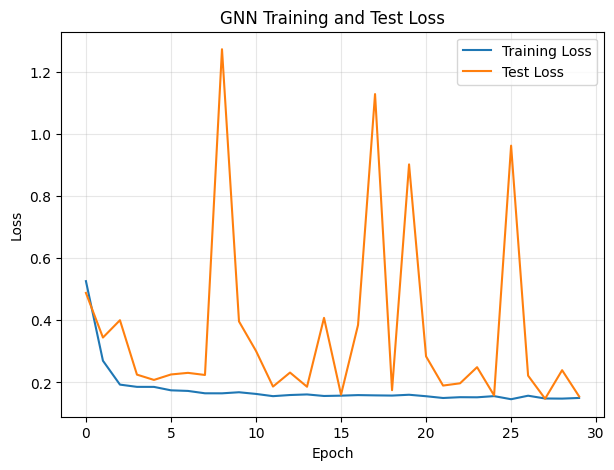

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GNN Training and Test Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [27]:
model.load_state_dict(best_state)
te_loss, te_acc, te_f1, te_cm = run_epoch(model, test_loader, optimizer=None, device=device)

print("Test loss", te_loss)
print("Test acc", te_acc)
print("Test f1", te_f1)
print("Test confusion matrix")
print(te_cm)


Test loss 0.10753130487600962
Test acc 0.972
Test f1 0.971736204576043
Test confusion matrix
[[368   7]
 [ 14 361]]


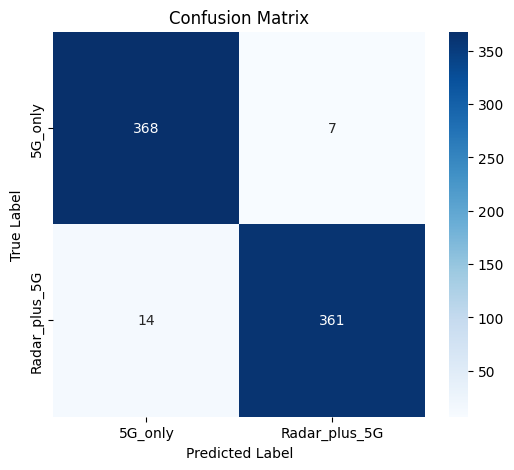

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

labels = ["5G_only", "Radar_plus_5G"]

plt.figure(figsize=(6,5))

sns.heatmap(
    te_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

In [29]:
from pathlib import Path
import torch

out = Path("saved_models")
out.mkdir(exist_ok=True)

ckpt = {
    "model_state": best_state,
    "label_map": label_map,
    "patch_h": 16,
    "patch_w": 16,
    "resize": (256,256),
    "model_name": GINClassifier,
    "best_val_f1": best_val_f1
}

torch.save(ckpt, out / "gin_radar_detector.pt")
print("Saved checkpoint")


Saved checkpoint


In [30]:
print(df.columns.tolist())
print(df.head(10).to_string())


['idx', 'class', 'radarType', 'radarIndex', 'filename', 'SNR_dB', 'SIR_dB', 'SINR_dB', 'UE1_x', 'UE1_y', 'UE1_z', 'UE2_x', 'UE2_y', 'UE2_z', 'UE3_x', 'UE3_y', 'UE3_z', 'gNB_x', 'gNB_y', 'gNB_z', 'radar_x', 'radar_y', 'radar_z', 'pathLossModel', 'numUE', 'numRx', 'path', 'y', 'W', 'H']
       idx          class radarType  radarIndex                                              filename   SNR_dB  SIR_dB  SINR_dB      UE1_x      UE1_y  UE1_z      UE2_x      UE2_y  UE2_z      UE3_x     UE3_y  UE3_z  gNB_x  gNB_y  gNB_z  radar_x  radar_y  radar_z pathLossModel  numUE  numRx                                                                        path  y     W     H
1501  1502        5G_only       NaN           0           5G_only_None_SNR+3p9_SIRNA_example_1502.png   3.8738     NaN   3.8738  -591.4842   193.9515    0.0  -991.0349   982.2161    0.0    94.8885  104.7886    0.0    0.0    0.0    0.0   3000.0    400.0      0.0           UMa      3      4                 dataset/5G_only/5G_only_Non

In [31]:
import torch
from PIL import Image
import numpy as np
from graph_utils import image_to_graph
from model import GINClassifier

ckpt = torch.load("saved_models/gin_radar_detector.pt", map_location="cpu", weights_only=False)

model = GINClassifier(in_dim=4, hidden=32, num_layers=4, num_classes=2, dropout=0.)
model.load_state_dict(ckpt["model_state"])
model.eval()

img = Image.open("/home/vmasc/Documents/ECE883_Digital_Image_processing/Final_project/dataset/Radar_plus_5G/Radar_plus_5G_FMCW_SNR+0p0_SIR+4p7_example_1994.png").convert("L").resize(ckpt["resize"])
img = np.array(img)

data = image_to_graph(img, y=0, patch_size=32)
with torch.no_grad():
    logits = model(data)
    pred = int(logits.argmax(dim=1))
inv = {v:k for k,v in ckpt["label_map"].items()}
print("Prediction:", inv[pred])
print('Accuracy', ckpt['best_val_f1'])


Prediction: Radar_plus_5G
Accuracy 0.956661316211878


In [32]:
for column in df.columns:
    print(column, ":", df[column].iloc[0])

idx : 1502
class : 5G_only
radarType : nan
radarIndex : 0
filename : 5G_only_None_SNR+3p9_SIRNA_example_1502.png
SNR_dB : 3.8738
SIR_dB : nan
SINR_dB : 3.8738
UE1_x : -591.4842
UE1_y : 193.9515
UE1_z : 0.0
UE2_x : -991.0349
UE2_y : 982.2161
UE2_z : 0.0
UE3_x : 94.8885
UE3_y : 104.7886
UE3_z : 0.0
gNB_x : 0.0
gNB_y : 0.0
gNB_z : 0.0
radar_x : 3000.0
radar_y : 400.0
radar_z : 0.0
pathLossModel : UMa
numUE : 3
numRx : 4
path : dataset/5G_only/5G_only_None_SNR+3p9_SIRNA_example_1502.png
y : 0
W : 2399
H : 1024


In [33]:
print(
    df[
        ["filename", "class", "SIR_dB"]
    ].head(20).to_string(index=False)
)

                                            filename         class  SIR_dB
         5G_only_None_SNR+3p9_SIRNA_example_1502.png       5G_only     NaN
Radar_plus_5G_FMCW_SNR+22p2_SIR-3p8_example_0087.png Radar_plus_5G -3.7797
 Radar_plus_5G_LFM_SNR+14p0_SIR+9p9_example_0154.png Radar_plus_5G  9.8502
         5G_only_None_SNR+5p3_SIRNA_example_1056.png       5G_only     NaN
        5G_only_None_SNR+17p8_SIRNA_example_0706.png       5G_only     NaN
         5G_only_None_SNR+0p1_SIRNA_example_0107.png       5G_only     NaN
        5G_only_None_SNR+16p3_SIRNA_example_0590.png       5G_only     NaN
        5G_only_None_SNR+11p7_SIRNA_example_2469.png       5G_only     NaN
        5G_only_None_SNR+17p1_SIRNA_example_2414.png       5G_only     NaN
        5G_only_None_SNR+13p5_SIRNA_example_1601.png       5G_only     NaN
        5G_only_None_SNR+23p8_SIRNA_example_2465.png       5G_only     NaN
         5G_only_None_SNR+4p1_SIRNA_example_0229.png       5G_only     NaN
         5G_only_None_SNR

In [34]:
radar_df = df[df["class"] == 1]

print(
    radar_df[
        ["filename", "class", "SIR_dB"]
    ].sample(
        n=min(10, len(radar_df)),
        random_state=42
    ).to_string(index=False)
)

Empty DataFrame
Columns: [filename, class, SIR_dB]
Index: []


In [35]:
import importlib
import dataset_pyg as dt

importlib.reload(dt)

<module 'dataset_pyg' from '/home/vmasc/Documents/ECE883_Digital_Image_processing/Final_project/dataset_pyg.py'>

In [36]:
sample = test_set[0]

print(sample)
print("Available fields:", sample.keys())
print("Label:", sample.y.item())
print("SIR:", sample.sir_db.item())

Data(x=[256, 4], edge_index=[2, 5294], y=[1], sir_db=[1])
Available fields: ['y', 'edge_index', 'sir_db', 'x']
Label: 0
SIR: 0.0


In [37]:
test_loader = DataLoader(
    test_set,
    batch_size=124,
    shuffle=False
)

batch = next(iter(test_loader))

print("Graphs:", batch.num_graphs)
print("Labels shape:", batch.y.view(-1).shape)
print("SIR shape:", batch.sir_db.view(-1).shape)
print("First labels:", batch.y.view(-1)[:10])
print("First SIR values:", batch.sir_db.view(-1)[:10])

assert batch.y.numel() == batch.num_graphs
assert batch.sir_db.numel() == batch.num_graphs

print("Batch mapping passed.")

Graphs: 124
Labels shape: torch.Size([124])
SIR shape: torch.Size([124])
First labels: tensor([0, 0, 1, 1, 0, 0, 1, 0, 1, 1])
First SIR values: tensor([ 0.0000,  0.0000, -6.9880, -9.2478,  0.0000,  0.0000,  2.6415,  0.0000,
         3.5599,  1.6935])
Batch mapping passed.


In [38]:
checkpoint_path = out / "gin_radar_detector.pt"

ckpt = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(ckpt))

if isinstance(ckpt, dict):
    print("Checkpoint keys:", ckpt.keys())

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model_state', 'label_map', 'patch_h', 'patch_w', 'resize', 'model_name', 'best_val_f1'])


In [39]:
print("Checkpoint type:", type(ckpt))

if isinstance(ckpt, dict):
    print("Checkpoint keys:", ckpt.keys())

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model_state', 'label_map', 'patch_h', 'patch_w', 'resize', 'model_name', 'best_val_f1'])


In [40]:
print("model_state type:", type(ckpt["model_state"]))
print("Label map:", ckpt["label_map"])
print("Patch size:", ckpt["patch_h"], ckpt["patch_w"])
print("Resize:", ckpt["resize"])
print("Model name:", ckpt["model_name"])
print("Best validation F1:", ckpt["best_val_f1"])

model_state type: <class 'dict'>
Label map: {'5G_only': 0, 'Radar_plus_5G': 1}
Patch size: 16 16
Resize: (256, 256)
Model name: <class 'model.GINClassifier'>
Best validation F1: 0.956661316211878


In [41]:
import inspect

ModelClass = ckpt["model_name"]

print(inspect.signature(ModelClass))

(in_dim=4, hidden=64, num_layers=4, num_classes=2, dropout=0.2)


In [42]:
import inspect

ModelClass = ckpt["model_name"]

print(inspect.signature(ModelClass))

sgin_model = ModelClass(
    in_dim=4,
    hidden=32,
    num_layers=4,
    num_classes=2,
    dropout=0.2
).to(device)

(in_dim=4, hidden=64, num_layers=4, num_classes=2, dropout=0.2)


In [43]:
sgin_model.load_state_dict(
    ckpt["model_state"]
)

sgin_model.eval()

print("Checkpoint loaded successfully.")

Checkpoint loaded successfully.


In [44]:
import time

sgin_model.eval()

times = []

with torch.no_grad():
    for data in test_loader:
        start = time.perf_counter()

        _ = sgin_model(data)

        end = time.perf_counter()

        times.append((end - start) * 1000)  # milliseconds

print(f"Average inference time per batch: {sum(times)/len(times):.3f} ms")

Average inference time per batch: 74.967 ms


In [45]:
test_dataset = dt.SpectrogramGraphDataset(
    test_df,
    resize=tuple(ckpt["resize"]),
    patch_size=ckpt["patch_h"]
)

In [46]:
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [47]:
sample = test_dataset[0]

print("Graph fields:", sample.keys())
print("Node feature dimension:", sample.x.shape[1])
print("Label:", sample.y.item())
print("SIR:", sample.sir_db.item())

Graph fields: ['y', 'edge_index', 'sir_db', 'x']
Node feature dimension: 4
Label: 0
SIR: 0.0


In [48]:
batch = next(iter(test_loader)).to(device)

with torch.no_grad():
    logits = model(batch)
    predictions = logits.argmax(dim=1)

print("Logits shape:", logits.shape)
print("First predictions:", predictions[:10])
print("First labels:", batch.y.view(-1)[:10])
print("First SIR values:", batch.sir_db.view(-1)[:10])

Logits shape: torch.Size([64, 2])
First predictions: tensor([0, 0, 1, 0, 0, 1, 1, 0, 1, 1])
First labels: tensor([0, 0, 1, 1, 0, 0, 1, 0, 1, 1])
First SIR values: tensor([ 0.0000,  0.0000, -6.9880, -9.2478,  0.0000,  0.0000,  2.6415,  0.0000,
         3.5599,  1.6935])


In [49]:

import pandas as pd
import torch


def collect_predictions(model, loader, model_name, device):
    model.eval()
    records = []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)

            logits = model(batch)
            predictions = logits.argmax(dim=1)

            labels = batch.y.view(-1)
            sir_values = batch.sir_db.view(-1)

            assert predictions.numel() == labels.numel()
            assert labels.numel() == sir_values.numel()

            for label, prediction, sir in zip(
                labels.cpu().tolist(),
                predictions.cpu().tolist(),
                sir_values.cpu().tolist()
            ):
                records.append({
                    "model": model_name,
                    "true_label": int(label),
                    "prediction": int(prediction),
                    "SIR_dB": float(sir)
                })

    return pd.DataFrame(records)
sgin_predictions = collect_predictions(
    model=sgin_model,
    loader=test_loader,
    model_name="sGIN",
    device=device
)

print(sgin_predictions.head())
print("Total predictions:", len(sgin_predictions))

  model  true_label  prediction  SIR_dB
0  sGIN           0           0  0.0000
1  sGIN           0           0  0.0000
2  sGIN           1           1 -6.9880
3  sGIN           1           0 -9.2478
4  sGIN           0           0  0.0000
Total predictions: 750


In [50]:
print("\nDataset and prediction sizes:")
print("Test dataset:", len(test_dataset))
print("Predictions:", len(sgin_predictions))

assert len(sgin_predictions) == len(test_dataset)

print("\nTrue-label counts:")
print(sgin_predictions["true_label"].value_counts())

print("\nPredicted-label counts:")
print(sgin_predictions["prediction"].value_counts())

print("\nSIR summary:")
print(sgin_predictions["SIR_dB"].describe())

print("\nUnique SIR values:")
print(
    sorted(
        sgin_predictions["SIR_dB"]
        .dropna()
        .unique()
    )
)


Dataset and prediction sizes:
Test dataset: 750
Predictions: 750

True-label counts:
true_label
0    375
1    375
Name: count, dtype: int64

Predicted-label counts:
prediction
0    382
1    368
Name: count, dtype: int64

SIR summary:
count    750.000000
mean       0.121668
std        4.128946
min       -9.707000
25%        0.000000
50%        0.000000
75%        0.286225
max        9.963800
Name: SIR_dB, dtype: float64

Unique SIR values:
[np.float64(-9.706999778747559), np.float64(-9.703399658203125), np.float64(-9.685199737548828), np.float64(-9.450200080871582), np.float64(-9.441900253295898), np.float64(-9.332599639892578), np.float64(-9.325900077819824), np.float64(-9.318900108337402), np.float64(-9.296299934387207), np.float64(-9.24779987335205), np.float64(-9.21150016784668), np.float64(-9.165300369262695), np.float64(-9.159000396728516), np.float64(-9.121700286865234), np.float64(-9.067700386047363), np.float64(-9.060999870300293), np.float64(-9.045900344848633), np.float64(-8

In [51]:
import numpy as np

assert np.array_equal(
    sgin_predictions["true_label"].to_numpy(),
    test_df["y"].astype(int).to_numpy()
)

assert np.allclose(
    sgin_predictions["SIR_dB"].to_numpy(),
    test_df["SIR_dB"].astype(float).to_numpy(),
    equal_nan=True
)

print("\nPrediction-to-SIR alignment passed.")


Prediction-to-SIR alignment passed.


In [52]:
# Keep radar-present samples only
radar_predictions = sgin_predictions[
    sgin_predictions["true_label"] == 1
].copy()

# Display each SIR value and its number of radar samples
sir_counts = (
    radar_predictions["SIR_dB"]
    .value_counts()
    .sort_index()
)

print("SIR values and radar-sample counts:")
print(sir_counts)

print("\nNumber of unique SIR values:")
print(radar_predictions["SIR_dB"].nunique())

print("\nMinimum SIR:")
print(radar_predictions["SIR_dB"].min())

print("\nMaximum SIR:")
print(radar_predictions["SIR_dB"].max())

SIR values and radar-sample counts:
SIR_dB
-9.7070    1
-9.7034    1
-9.6852    1
-9.4502    1
-9.4419    1
          ..
 9.7620    1
 9.8520    1
 9.9274    1
 9.9347    1
 9.9638    1
Name: count, Length: 374, dtype: int64

Number of unique SIR values:
374

Minimum SIR:
-9.706999778747559

Maximum SIR:
9.963800430297852


In [53]:
import numpy as np
import pandas as pd

bucket_edges = np.arange(-10, 12, 2)
bucket_centers = np.arange(-9, 11, 2)

print("Edges:", bucket_edges)
print("Centers:", bucket_centers)

Edges: [-10  -8  -6  -4  -2   0   2   4   6   8  10]
Centers: [-9 -7 -5 -3 -1  1  3  5  7  9]


In [54]:
# from torchvision import datasets, transforms
# from torch.utils.data import random_split, DataLoader
# import torch

# transform = transforms.Compose([
#     transforms.Grayscale(num_output_channels=1),
#     transforms.Resize((256, 256)),
#     transforms.ToTensor()
# ])

# dataset = datasets.ImageFolder(
#     root="dataset",
#     transform=transform
# )

# # Sizes
# train_size = int(0.7 * len(dataset))
# val_size = int(0.15 * len(dataset))
# test_size = int(0.15 * len(dataset))

# # Split
# train_dataset, val_dataset, test_dataset = random_split(
#     dataset,
#     [train_size, val_size, test_size],
#     generator=torch.Generator().manual_seed(42)
# )

# # Loaders
# train_loader = DataLoader(
#     train_dataset,
#     batch_size=124,
#     shuffle=True
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=124,
#     shuffle=False
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=124,
#     shuffle=False
# )

In [55]:
radar_predictions["SIR_bucket"] = pd.cut(
    radar_predictions["SIR_dB"],
    bins=bucket_edges,
    labels=bucket_centers,
    include_lowest=True,
    right=False
)

In [56]:
radar_predictions.loc[
    radar_predictions["SIR_dB"] == 10,
    "SIR_bucket"
] = 9

In [57]:
radar_predictions["SIR_bucket"] = (
    radar_predictions["SIR_bucket"]
    .astype(float)
)

In [58]:
print("Total radar samples:", len(radar_predictions))

print(
    "Samples assigned to buckets:",
    radar_predictions["SIR_bucket"].notna().sum()
)

print(
    "Samples without a bucket:",
    radar_predictions["SIR_bucket"].isna().sum()
)

Total radar samples: 375
Samples assigned to buckets: 375
Samples without a bucket: 0


In [59]:
print(
    radar_predictions["SIR_bucket"]
    .value_counts()
    .sort_index()
)

SIR_bucket
-9.0    32
-7.0    43
-5.0    33
-3.0    40
-1.0    36
 1.0    30
 3.0    40
 5.0    41
 7.0    39
 9.0    41
Name: count, dtype: int64


In [60]:
# import torch
# import torch.nn as nn
# from torchvision.models import resnet18, ResNet18_Weights

# device = "cuda" if torch.cuda.is_available() else "cpu"

# model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# # Change first layer for grayscale images
# model.conv1 = nn.Conv2d(
#     1, 64,
#     kernel_size=7,
#     stride=2,
#     padding=3,
#     bias=False
# )

# # Change final layer for 2 classes
# model.fc = nn.Linear(model.fc.in_features, 2)

# model = model.to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [61]:
radar_predictions["detected"] = (
    radar_predictions["prediction"] == 1
).astype(int)

In [62]:
# num_epochs = 30
# best_val_loss = float("inf")

# for epoch in range(num_epochs):
#     model.train()
#     train_loss = 0
#     correct = 0
#     total = 0

#     for images, labels in train_loader:
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#         _, predicted = torch.max(outputs, 1)
#         correct += (predicted == labels).sum().item()
#         total += labels.size(0)

#     train_acc = correct / total
#     train_loss = train_loss / len(train_loader)

#     # Validation
#     model.eval()
#     val_loss = 0
#     val_correct = 0
#     val_total = 0

#     with torch.no_grad():
#         for images, labels in test_loader:
#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             val_loss += loss.item()

#             _, predicted = torch.max(outputs, 1)
#             val_correct += (predicted == labels).sum().item()
#             val_total += labels.size(0)

#     val_acc = val_correct / val_total
#     val_loss = val_loss / len(test_loader)

#     print(
#         f"Epoch [{epoch+1}/{num_epochs}] "
#         f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} "
#         f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}"
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         torch.save(model.state_dict(), "best_resnet18_model.pt")

In [63]:
print(
    radar_predictions[
        [
            "true_label",
            "prediction",
            "SIR_dB",
            "SIR_bucket",
            "detected"
        ]
    ].head(15)
)

    true_label  prediction  SIR_dB  SIR_bucket  detected
2            1           1 -6.9880        -7.0         1
3            1           0 -9.2478        -9.0         0
6            1           1  2.6415         3.0         1
8            1           1  3.5599         3.0         1
9            1           1  1.6935         1.0         1
11           1           1 -3.6880        -3.0         1
14           1           1  9.5657         9.0         1
18           1           1  7.0655         7.0         1
19           1           1  8.9127         9.0         1
20           1           1 -6.5648        -7.0         1
23           1           1  9.0538         9.0         1
24           1           1 -4.4622        -5.0         1
28           1           1  2.1538         3.0         1
29           1           1  0.6206         1.0         1
30           1           1 -5.4963        -5.0         1


In [64]:
sgin_pd = (
    radar_predictions
    .groupby("SIR_bucket", observed=True)
    .agg(
        TP=("detected", "sum"),
        total_radar=("detected", "count"),
        Pd=("detected", "mean")
    )
    .reset_index()
    .sort_values("SIR_bucket")
)

sgin_pd["FN"] = (
    sgin_pd["total_radar"] -
    sgin_pd["TP"]
)

print(sgin_pd)

   SIR_bucket  TP  total_radar        Pd  FN
0        -9.0  27           32  0.843750   5
1        -7.0  40           43  0.930233   3
2        -5.0  31           33  0.939394   2
3        -3.0  36           40  0.900000   4
4        -1.0  36           36  1.000000   0
5         1.0  30           30  1.000000   0
6         3.0  40           40  1.000000   0
7         5.0  41           41  1.000000   0
8         7.0  39           39  1.000000   0
9         9.0  41           41  1.000000   0


In [65]:
lowest_bucket = radar_predictions[
    radar_predictions["SIR_bucket"] == -9
]

tp = (lowest_bucket["prediction"] == 1).sum()
fn = (lowest_bucket["prediction"] == 0).sum()

manual_pd = tp / (tp + fn)

print("TP:", tp)
print("FN:", fn)
print("Manual Pd:", manual_pd)

print("\nCalculated table:")
print(sgin_pd[sgin_pd["SIR_bucket"] == -9])

TP: 27
FN: 5
Manual Pd: 0.84375

Calculated table:
   SIR_bucket  TP  total_radar       Pd  FN
0        -9.0  27           32  0.84375   5


In [66]:
# import time
# import numpy as np
# import torch

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = model.to(device)
# model.eval()

# batch_times = []
# per_image_times = []

# with torch.no_grad():
#     for images, labels in test_loader:

#         images = images.to(device)

#         if device.type == "cuda":
#             torch.cuda.synchronize()

#         start = time.perf_counter()

#         outputs = model(images)

#         if device.type == "cuda":
#             torch.cuda.synchronize()

#         end = time.perf_counter()

#         elapsed_ms = (end - start) * 1000

#         batch_times.append(elapsed_ms)
#         per_image_times.append(elapsed_ms / images.size(0))

# print(f"Average batch inference time: {np.mean(batch_times):.4f} ms")
# print(f"Average inference time per image: {np.mean(per_image_times):.4f} ms")

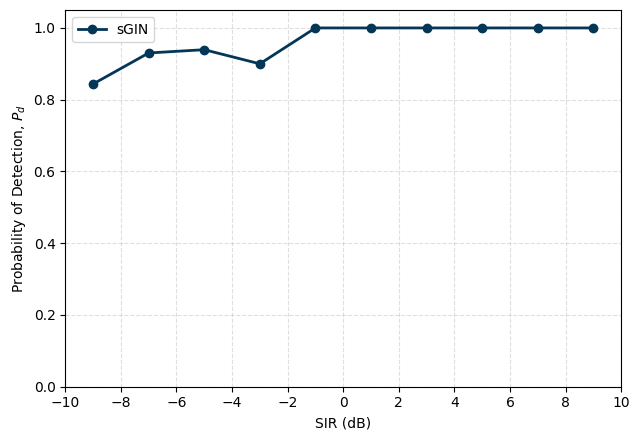

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6.5, 4.5))

plt.plot(
    sgin_pd["SIR_bucket"],
    sgin_pd["Pd"],
    marker="o",
    markersize=6,
    linewidth=2,
    color="#043657",
    label="sGIN"
)

plt.xlabel("SIR (dB)")
plt.ylabel(r"Probability of Detection, $P_d$")
plt.xlim(-10, 10)
plt.ylim(0, 1.05)
plt.xticks(np.arange(-10, 11, 2))
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)
plt.legend()
plt.tight_layout()
plt.show()

In [68]:
# from sklearn.metrics import f1_score, confusion_matrix
# import torch

# # Load best model
# model.load_state_dict(torch.load("best_resnet18_model.pt", map_location=device))
# model = model.to(device)

# model.eval()

# test_loss = 0
# correct = 0
# total = 0

# all_preds = []
# all_labels = []

# with torch.no_grad():
#     for images, labels in test_loader:
#         images = images.to(device)
#         labels = labels.to(device)

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         test_loss += loss.item()

#         _, predicted = torch.max(outputs, 1)

#         correct += (predicted == labels).sum().item()
#         total += labels.size(0)

#         all_preds.extend(predicted.cpu().numpy())
#         all_labels.extend(labels.cpu().numpy())

# test_loss = test_loss / len(test_loader)
# test_acc = correct / total
# test_f1 = f1_score(all_labels, all_preds)
# cm = confusion_matrix(all_labels, all_preds)

# print("Test loss:", test_loss)
# print("Test acc:", test_acc)
# print("Test f1:", test_f1)
# print("Test confusion matrix:")
# print(cm)

In [69]:
sgin_pd.to_csv(
    "sgin_pd_vs_sir_2db_buckets.csv",
    index=False
)

radar_predictions.to_csv(
    "sgin_radar_predictions_with_buckets.csv",
    index=False
)

In [70]:
def calculate_pd_by_sir(
    predictions_df,
    positive_class=1
):
    radar_df = predictions_df[
        predictions_df["true_label"] == positive_class
    ].copy()

    bucket_edges = np.arange(-10, 12, 2)
    bucket_centers = np.arange(-9, 11, 2)

    radar_df["SIR_bucket"] = pd.cut(
        radar_df["SIR_dB"],
        bins=bucket_edges,
        labels=bucket_centers,
        include_lowest=True,
        right=False
    ).astype(float)

    radar_df["detected"] = (
        radar_df["prediction"] == positive_class
    ).astype(int)

    results = (
        radar_df
        .groupby(
            ["model", "SIR_bucket"],
            observed=True
        )
        .agg(
            TP=("detected", "sum"),
            total_radar=("detected", "count"),
            Pd=("detected", "mean")
        )
        .reset_index()
        .sort_values(["model", "SIR_bucket"])
    )

    results["FN"] = (
        results["total_radar"] -
        results["TP"]
    )

    return results

In [71]:
# TP, FN, FP, TN = cm.ravel()

# Pd = TP / (TP + FN)
# Pfa = FP / (FP + TN)

# print("Pd:", Pd)
# print("Pfa:", Pfa)

In [72]:
sgin_pd_check = calculate_pd_by_sir(
    sgin_predictions
)

print(sgin_pd_check)

  model  SIR_bucket  TP  total_radar        Pd  FN
0  sGIN        -9.0  27           32  0.843750   5
1  sGIN        -7.0  40           43  0.930233   3
2  sGIN        -5.0  31           33  0.939394   2
3  sGIN        -3.0  36           40  0.900000   4
4  sGIN        -1.0  36           36  1.000000   0
5  sGIN         1.0  30           30  1.000000   0
6  sGIN         3.0  40           40  1.000000   0
7  sGIN         5.0  41           41  1.000000   0
8  sGIN         7.0  39           39  1.000000   0
9  sGIN         9.0  41           41  1.000000   0


### GCN Pd vs SIR

In [73]:
gcn_checkpoint_path = out / "gcn_radar_detector.pt"

gcn_ckpt = torch.load(
    gcn_checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(gcn_ckpt))

if isinstance(gcn_ckpt, dict):
    print("Checkpoint keys:", gcn_ckpt.keys())

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model_state', 'label_map', 'patch_h', 'patch_w', 'resize', 'model_name', 'best_val_f1'])


In [74]:
import inspect

ModelClass = gcn_ckpt["model_name"]

print(inspect.signature(ModelClass))

sgcn_model = ModelClass(
    in_dim=4,
    hidden=64,
    num_layers=4,
    num_classes=2,
    dropout=0.2
).to(device)
for key, value in gcn_ckpt.items():
    if key == "model_state":
        print(key, type(value))
    else:
        print(key, value)


(in_dim=4, hidden=64, num_layers=4, num_classes=2, dropout=0.2)
model_state <class 'dict'>
label_map {'5G_only': 0, 'Radar_plus_5G': 1}
patch_h 16
patch_w 16
resize (256, 256)
model_name <class 'model_copy.GINClassifier'>
best_val_f1 0.9614147909967846


In [75]:
gcn_predictions = collect_predictions(
    model=sgcn_model,
    loader=test_loader,
    model_name="GCN",
    device=device
)
print("Total GCN predictions:", len(gcn_predictions))

print(
    gcn_predictions[
        gcn_predictions["true_label"] == 1
    ].shape[0]
)

Total GCN predictions: 750
375


In [ ]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

data_dir = "dataset"
classes = ["5G_only", "Radar_plus_5G"]

X = []
y = []

img_size = (128, 128)  # smaller size is better for logistic regression

for label, class_name in enumerate(classes):
    class_folder = os.path.join(data_dir, class_name)

    for file in os.listdir(class_folder):
        if file.lower().endswith((".png", ".jpg", ".jpeg")):
            img_path = os.path.join(class_folder, file)

            img = Image.open(img_path).convert("L")
            img = img.resize(img_size)

            img_array = np.array(img) / 255.0
            img_flat = img_array.flatten()

            X.append(img_flat)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
logreg = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    class_weight="balanced"
)

logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=classes, digits=4))

In [ ]:
# pip install scikit-learn

In [ ]:
import numpy as np
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# =========================
# TRAIN / TEST SPLIT BY SINR
# =========================

train_df = df[df['SIR_dB'] >= -5]

test_df  = df[df['SIR_dB'] < -5]

print("Train samples:", len(train_df))
print("Test samples :", len(test_df))

# =========================
# IMAGE LOADING FUNCTION
# =========================

def load_images(dataframe, img_size=(128,128)):

    X = []
    y = []

    for _, row in dataframe.iterrows():

        img = Image.open(row['path']).convert("L")
        img = img.resize(img_size)

        img_array = np.array(img) / 255.0

        X.append(img_array.flatten())
        y.append(row['class'])

    return np.array(X), np.array(y)

# Load train/test data
X_train, y_train = load_images(train_df)
X_test, y_test   = load_images(test_df)

# =========================
# NORMALIZATION
# =========================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# =========================
# TRAIN MODEL
# =========================

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

# =========================
# EVALUATE
# =========================

y_pred = model.predict(X_test)

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

### RESNET SIR Vs PD

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

device = "cuda" if torch.cuda.is_available() else "cpu"

# Architecture only; saved weights will be loaded below
resnet_model = resnet18(weights=None)

# Same grayscale input layer used during training
resnet_model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

# Same two-class output layer
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    2
)

resnet_model = resnet_model.to(device)

resnet_state = torch.load(
    "best_resnet18_model.pt",
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(resnet_state)
resnet_model.eval()

print("ResNet18 checkpoint loaded successfully.")

ResNet18 checkpoint loaded successfully.


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import random_split
from torch.utils.data import DataLoader as TorchDataLoader
import torch

resnet_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

resnet_full_dataset = datasets.ImageFolder(
    root="dataset",
    transform=resnet_transform
)

train_size = int(0.70 * len(resnet_full_dataset))
val_size = int(0.15 * len(resnet_full_dataset))
test_size = len(resnet_full_dataset) - train_size - val_size

resnet_train_dataset, resnet_val_dataset, resnet_test_dataset = random_split(
    resnet_full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

resnet_test_loader = TorchDataLoader(
    resnet_test_dataset,
    batch_size=124,
    shuffle=False
)

print("Full dataset:", len(resnet_full_dataset))
print("ResNet train:", len(resnet_train_dataset))
print("ResNet validation:", len(resnet_val_dataset))
print("ResNet test:", len(resnet_test_dataset))

Full dataset: 5000
ResNet train: 3500
ResNet validation: 750
ResNet test: 750


In [ ]:
resnet_test_paths = [
    resnet_full_dataset.samples[index][0]
    for index in resnet_test_dataset.indices
]

resnet_test_labels = [
    resnet_full_dataset.samples[index][1]
    for index in resnet_test_dataset.indices
]

print(resnet_test_paths[:5])
print(resnet_test_labels[:5])

['dataset/Radar_plus_5G/Radar_plus_5G_NLFM_SNR+7p6_SIR-8p7_example_1357.png', 'dataset/5G_only/5G_only_None_SNR+15p1_SIRNA_example_2341.png', 'dataset/5G_only/5G_only_None_SNR+21p7_SIRNA_example_2188.png', 'dataset/Radar_plus_5G/Radar_plus_5G_NLFM_SNR+10p3_SIR-9p1_example_0850.png', 'dataset/5G_only/5G_only_None_SNR+4p6_SIRNA_example_0709.png']
[1, 0, 0, 1, 0]


In [ ]:
from pathlib import Path

metadata = df.copy()

metadata["normalized_path"] = metadata["path"].apply(
    lambda path: str(Path(path).resolve())
)

resnet_test_metadata = pd.DataFrame({
    "normalized_path": [
        str(Path(path).resolve())
        for path in resnet_test_paths
    ],
    "resnet_label": resnet_test_labels
})

In [ ]:
resnet_test_metadata = resnet_test_metadata.merge(
    metadata[
        [
            "normalized_path",
            "y",
            "SIR_dB"
        ]
    ],
    on="normalized_path",
    how="left",
    validate="one_to_one"
)

In [ ]:
print(resnet_test_metadata.head())

print(
    "Missing SIR values:",
    resnet_test_metadata["SIR_dB"].isna().sum()
)

print(
    "Label mismatches:",
    (
        resnet_test_metadata["resnet_label"] !=
        resnet_test_metadata["y"]
    ).sum()
)

                                     normalized_path  resnet_label  y  SIR_dB
0  /home/vmasc/Documents/ECE883_Digital_Image_pro...             1  1 -8.6596
1  /home/vmasc/Documents/ECE883_Digital_Image_pro...             0  0     NaN
2  /home/vmasc/Documents/ECE883_Digital_Image_pro...             0  0     NaN
3  /home/vmasc/Documents/ECE883_Digital_Image_pro...             1  1 -9.0512
4  /home/vmasc/Documents/ECE883_Digital_Image_pro...             0  0     NaN
Missing SIR values: 366
Label mismatches: 0


In [ ]:
def collect_resnet_predictions(
    model,
    loader,
    metadata_df,
    device
):
    model.eval()
    records = []
    offset = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.view(-1).long()

            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu()

            current_batch_size = labels.numel()

            batch_metadata = metadata_df.iloc[
                offset:offset + current_batch_size
            ]

            metadata_labels = (
                batch_metadata["y"]
                .astype(int)
                .to_numpy()
            )

            loader_labels = labels.numpy()

            assert np.array_equal(
                loader_labels,
                metadata_labels
            ), "Labels and metadata are misaligned."

            sir_values = (
                batch_metadata["SIR_dB"]
                .astype(float)
                .to_numpy()
            )

            for label, prediction, sir in zip(
                loader_labels,
                predictions.numpy(),
                sir_values
            ):
                records.append({
                    "model": "ResNet18",
                    "true_label": int(label),
                    "prediction": int(prediction),
                    "SIR_dB": float(sir)
                })

            offset += current_batch_size

    assert offset == len(metadata_df)

    return pd.DataFrame(records)

In [ ]:
resnet_predictions = collect_resnet_predictions(
    model=resnet_model,
    loader=resnet_test_loader,
    metadata_df=resnet_test_metadata,
    device=device
)

print(resnet_predictions.head())
print("Total predictions:", len(resnet_predictions))
print(
    "Radar samples:",
    (resnet_predictions["true_label"] == 1).sum()
)

      model  true_label  prediction  SIR_dB
0  ResNet18           1           1 -8.6596
1  ResNet18           0           1     NaN
2  ResNet18           0           0     NaN
3  ResNet18           1           1 -9.0512
4  ResNet18           0           1     NaN
Total predictions: 750
Radar samples: 384


In [ ]:
sgin_paths = set(
    test_df["path"].apply(
        lambda path: str(Path(path).resolve())
    )
)

resnet_paths = set(
    resnet_test_metadata["normalized_path"]
)

print("sGIN test samples:", len(sgin_paths))
print("ResNet test samples:", len(resnet_paths))
print("Shared test samples:", len(sgin_paths & resnet_paths))
print("Same test set:", sgin_paths == resnet_paths)

sGIN test samples: 750
ResNet test samples: 750
Shared test samples: 119
Same test set: False


In [ ]:
resnet_pd = calculate_pd_by_sir(
    resnet_predictions
)

print(resnet_pd)

      model  SIR_bucket  TP  total_radar        Pd  FN
0  ResNet18        -9.0  41           41  1.000000   0
1  ResNet18        -7.0  40           40  1.000000   0
2  ResNet18        -5.0  43           44  0.977273   1
3  ResNet18        -3.0  39           39  1.000000   0
4  ResNet18        -1.0  38           38  1.000000   0
5  ResNet18         1.0  34           34  1.000000   0
6  ResNet18         3.0  45           45  1.000000   0
7  ResNet18         5.0  35           36  0.972222   1
8  ResNet18         7.0  31           33  0.939394   2
9  ResNet18         9.0  30           34  0.882353   4


In [ ]:
print(
    "ResNet radar samples:",
    resnet_pd["total_radar"].sum()
)

ResNet radar samples: 384


In [ ]:
sgin_pd = calculate_pd_by_sir(
    sgin_predictions
)

gcn_pd = calculate_pd_by_sir(
    gcn_predictions
)

In [ ]:
print("\nsGIN:")
print(sgin_pd)

print("\nGCN:")
print(gcn_pd)

print("\nResNet18:")
print(resnet_pd)


sGIN:
  model  SIR_bucket  TP  total_radar        Pd  FN
0  sGIN        -9.0  26           32  0.812500   6
1  sGIN        -7.0  40           43  0.930233   3
2  sGIN        -5.0  32           33  0.969697   1
3  sGIN        -3.0  36           40  0.900000   4
4  sGIN        -1.0  36           36  1.000000   0
5  sGIN         1.0  30           30  1.000000   0
6  sGIN         3.0  40           40  1.000000   0
7  sGIN         5.0  41           41  1.000000   0
8  sGIN         7.0  39           39  1.000000   0
9  sGIN         9.0  41           41  1.000000   0

GCN:
  model  SIR_bucket  TP  total_radar   Pd  FN
0   GCN        -9.0  32           32  1.0   0
1   GCN        -7.0  43           43  1.0   0
2   GCN        -5.0  33           33  1.0   0
3   GCN        -3.0  40           40  1.0   0
4   GCN        -1.0  36           36  1.0   0
5   GCN         1.0  30           30  1.0   0
6   GCN         3.0  40           40  1.0   0
7   GCN         5.0  41           41  1.0   0
8   GCN     

In [ ]:
assert len(sgin_pd) == 10
assert len(gcn_pd) == 10
assert len(resnet_pd) == 10

print("All models contain ten SIR buckets.")

All models contain ten SIR buckets.


In [ ]:
all_pd = pd.concat(
    [
        sgin_pd,
        gcn_pd,
        resnet_pd
    ],
    ignore_index=True
)

print(all_pd)

       model  SIR_bucket  TP  total_radar        Pd  FN
0       sGIN        -9.0  26           32  0.812500   6
1       sGIN        -7.0  40           43  0.930233   3
2       sGIN        -5.0  32           33  0.969697   1
3       sGIN        -3.0  36           40  0.900000   4
4       sGIN        -1.0  36           36  1.000000   0
5       sGIN         1.0  30           30  1.000000   0
6       sGIN         3.0  40           40  1.000000   0
7       sGIN         5.0  41           41  1.000000   0
8       sGIN         7.0  39           39  1.000000   0
9       sGIN         9.0  41           41  1.000000   0
10       GCN        -9.0  32           32  1.000000   0
11       GCN        -7.0  43           43  1.000000   0
12       GCN        -5.0  33           33  1.000000   0
13       GCN        -3.0  40           40  1.000000   0
14       GCN        -1.0  36           36  1.000000   0
15       GCN         1.0  30           30  1.000000   0
16       GCN         3.0  40           40  1.000

In [ ]:
print(all_pd["model"].unique())

<StringArray>
['sGIN', 'GCN', 'ResNet18']
Length: 3, dtype: str


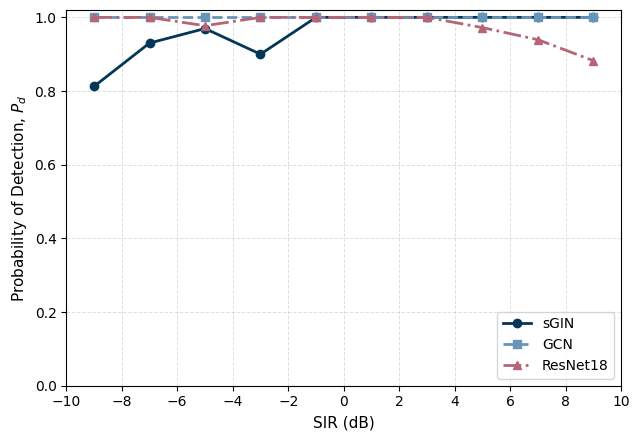

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

styles = {
    "sGIN": {
        "color": "#043657",
        "marker": "o",
        "linestyle": "-"
    },
    "GCN": {
        "color": "#6795b8",
        "marker": "s",
        "linestyle": "--"
    },
    "ResNet18": {
        "color": "#b56576",
        "marker": "^",
        "linestyle": "-."
    }
}

fig, ax = plt.subplots(figsize=(6.5, 4.5))

for model_name in ["sGIN", "GCN", "ResNet18"]:
    model_results = all_pd[
        all_pd["model"] == model_name
    ].sort_values("SIR_bucket")

    ax.plot(
        model_results["SIR_bucket"],
        model_results["Pd"],
        color=styles[model_name]["color"],
        marker=styles[model_name]["marker"],
        linestyle=styles[model_name]["linestyle"],
        linewidth=2,
        markersize=6,
        label=model_name
    )

ax.set_xlabel("SIR (dB)", fontsize=11)
ax.set_ylabel(
    r"Probability of Detection, $P_d$",
    fontsize=11
)

ax.set_xlim(-10, 10)
ax.set_ylim(0, 1.02)

ax.set_xticks(
    np.arange(-10, 11, 2)
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.4
)

ax.legend(
    loc="lower right",
    frameon=True,
    fontsize=10
)

fig.tight_layout()

fig.savefig(
    "pd_vs_sir_all_models.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "pd_vs_sir_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print(df.columns.tolist())

['idx', 'class', 'radarType', 'radarIndex', 'filename', 'SNR_dB', 'SIR_dB', 'SINR_dB', 'UE1_x', 'UE1_y', 'UE1_z', 'UE2_x', 'UE2_y', 'UE2_z', 'UE3_x', 'UE3_y', 'UE3_z', 'gNB_x', 'gNB_y', 'gNB_z', 'radar_x', 'radar_y', 'radar_z', 'pathLossModel', 'numUE', 'numRx', 'path', 'y', 'W', 'H']


In [ ]:
print(df["radarType"].value_counts(dropna=False))
print(df[["path", "y", "radarType"]].head(20))

radarType
NaN     2500
FMCW     650
P4       649
LFM      607
NLFM     594
Name: count, dtype: int64
                                                   path  y radarType
1501  dataset/5G_only/5G_only_None_SNR+3p9_SIRNA_exa...  0       NaN
2586  dataset/Radar_plus_5G/Radar_plus_5G_FMCW_SNR+2...  1      FMCW
2653  dataset/Radar_plus_5G/Radar_plus_5G_LFM_SNR+14...  1       LFM
1055  dataset/5G_only/5G_only_None_SNR+5p3_SIRNA_exa...  0       NaN
705   dataset/5G_only/5G_only_None_SNR+17p8_SIRNA_ex...  0       NaN
106   dataset/5G_only/5G_only_None_SNR+0p1_SIRNA_exa...  0       NaN
589   dataset/5G_only/5G_only_None_SNR+16p3_SIRNA_ex...  0       NaN
2468  dataset/5G_only/5G_only_None_SNR+11p7_SIRNA_ex...  0       NaN
2413  dataset/5G_only/5G_only_None_SNR+17p1_SIRNA_ex...  0       NaN
1600  dataset/5G_only/5G_only_None_SNR+13p5_SIRNA_ex...  0       NaN
2464  dataset/5G_only/5G_only_None_SNR+23p8_SIRNA_ex...  0       NaN
228   dataset/5G_only/5G_only_None_SNR+4p1_SIRNA_exa...  0       NaN
91

In [ ]:
radar_metadata = df[
    df["y"] == 1
].copy()

print(
    radar_metadata["radarType"]
    .value_counts(dropna=False)
)

radarType
FMCW    650
P4      649
LFM     607
NLFM    594
Name: count, dtype: int64


In [ ]:
print(
    radar_metadata["radarType"]
    .astype(str)
    .unique()
)

<StringArray>
['FMCW', 'LFM', 'P4', 'NLFM']
Length: 4, dtype: str


In [ ]:
print(
    radar_metadata["radarType"]
    .astype(str)
    .unique()
)

<StringArray>
['FMCW', 'LFM', 'P4', 'NLFM']
Length: 4, dtype: str


In [ ]:
print(df["radarType"].value_counts())

radarType
FMCW    650
P4      649
LFM     607
NLFM    594
Name: count, dtype: int64


In [ ]:
assert len(sgin_predictions) == len(test_df)

assert np.array_equal(
    sgin_predictions["true_label"].to_numpy(),
    test_df["y"].astype(int).to_numpy()
)

print("sGIN metadata alignment passed.")

sGIN metadata alignment passed.


In [ ]:
sgin_predictions["radarType"] = (
    test_df["radarType"]
    .astype(str)
    .str.strip()
    .str.upper()
    .to_numpy()
)

In [ ]:
print(
    sgin_predictions[
        [
            "true_label",
            "prediction",
            "SIR_dB",
            "radarType"
        ]
    ].head()
)

   true_label  prediction  SIR_dB radarType
0           0           0  0.0000       NaN
1           0           0  0.0000       NaN
2           1           1 -6.9880      FMCW
3           1           0 -9.2478       LFM
4           0           0  0.0000       NaN


In [ ]:
assert len(gcn_predictions) == len(test_df)

assert np.array_equal(
    sgin_predictions["true_label"].to_numpy(),
    test_df["y"].astype(int).to_numpy()
)

print("sGIN metadata alignment passed.")

sGIN metadata alignment passed.


In [ ]:
gcn_predictions["radarType"] = (
    test_df["radarType"]
    .astype(str)
    .str.strip()
    .str.upper()
    .to_numpy()
)

In [ ]:
resnet_test_metadata = pd.DataFrame({
    "normalized_path": [
        str(Path(path).resolve())
        for path in resnet_test_paths
    ],
    "resnet_label": resnet_test_labels
})

resnet_test_metadata = resnet_test_metadata.merge(
    metadata[
        [
            "normalized_path",
            "y",
            "SIR_dB",
            "radarType"
        ]
    ],
    on="normalized_path",
    how="left",
    validate="one_to_one"
)

In [ ]:
print(
    resnet_test_metadata["radarType"]
    .value_counts(dropna=False)
)

radarType
NaN     366
P4      108
FMCW    104
NLFM     92
LFM      80
Name: count, dtype: int64


In [ ]:
assert len(resnet_predictions) == len(
    resnet_test_metadata
)

resnet_predictions["radarType"] = (
    resnet_test_metadata["radarType"]
    .astype(str)
    .str.strip()
    .str.upper()
    .to_numpy()
)

In [ ]:
for name, predictions in {
    "sGIN": sgin_predictions,
    "GCN": gcn_predictions,
    "ResNet18": resnet_predictions
}.items():

    radar_rows = predictions[
        predictions["true_label"] == 1
    ]

    print(f"\n{name}")
    print(
        radar_rows["radarType"]
        .value_counts(dropna=False)
    )


sGIN
radarType
FMCW    108
P4       92
LFM      88
NLFM     87
Name: count, dtype: int64

GCN
radarType
FMCW    108
P4       92
LFM      88
NLFM     87
Name: count, dtype: int64

ResNet18
radarType
P4      108
FMCW    104
NLFM     92
LFM      80
Name: count, dtype: int64


In [ ]:
EXPECTED_WAVEFORMS = [
    "LFM",
    "NLFM",
    "FMCW",
    "P4"
]


def calculate_pd_by_waveform(
    predictions_df,
    positive_class=1
):
    radar_df = predictions_df[
        predictions_df["true_label"] == positive_class
    ].copy()

    radar_df["radarType"] = (
        radar_df["radarType"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    radar_df["detected"] = (
        radar_df["prediction"] == positive_class
    ).astype(int)

    results = (
        radar_df
        .groupby(
            ["model", "radarType"],
            observed=True
        )
        .agg(
            TP=("detected", "sum"),
            total_radar=("detected", "count"),
            Pd=("detected", "mean")
        )
        .reset_index()
    )

    results["FN"] = (
        results["total_radar"] -
        results["TP"]
    )

    results["radarType"] = pd.Categorical(
        results["radarType"],
        categories=EXPECTED_WAVEFORMS,
        ordered=True
    )

    return results.sort_values(
        ["model", "radarType"]
    )

In [ ]:
sgin_waveform_pd = calculate_pd_by_waveform(
    sgin_predictions
)

gcn_waveform_pd = calculate_pd_by_waveform(
    gcn_predictions
)

resnet_waveform_pd = calculate_pd_by_waveform(
    resnet_predictions
)

all_waveform_pd = pd.concat(
    [
        sgin_waveform_pd,
        gcn_waveform_pd,
        resnet_waveform_pd
    ],
    ignore_index=True
)

print(all_waveform_pd)

       model radarType   TP  total_radar        Pd  FN
0       sGIN       LFM   81           88  0.920455   7
1       sGIN      NLFM   85           87  0.977011   2
2       sGIN      FMCW  105          108  0.972222   3
3       sGIN        P4   90           92  0.978261   2
4        GCN       LFM   88           88  1.000000   0
5        GCN      NLFM   87           87  1.000000   0
6        GCN      FMCW  108          108  1.000000   0
7        GCN        P4   92           92  1.000000   0
8   ResNet18       LFM   79           80  0.987500   1
9   ResNet18      NLFM   86           92  0.934783   6
10  ResNet18      FMCW  104          104  1.000000   0
11  ResNet18        P4  107          108  0.990741   1


In [ ]:
sgin_waveform_pd = calculate_pd_by_waveform(
    sgin_predictions
)

gcn_waveform_pd = calculate_pd_by_waveform(
    gcn_predictions
)

resnet_waveform_pd = calculate_pd_by_waveform(
    resnet_predictions
)

all_waveform_pd = pd.concat(
    [
        sgin_waveform_pd,
        gcn_waveform_pd,
        resnet_waveform_pd
    ],
    ignore_index=True
)

print(all_waveform_pd)

       model radarType   TP  total_radar        Pd  FN
0       sGIN       LFM   81           88  0.920455   7
1       sGIN      NLFM   85           87  0.977011   2
2       sGIN      FMCW  105          108  0.972222   3
3       sGIN        P4   90           92  0.978261   2
4        GCN       LFM   88           88  1.000000   0
5        GCN      NLFM   87           87  1.000000   0
6        GCN      FMCW  108          108  1.000000   0
7        GCN        P4   92           92  1.000000   0
8   ResNet18       LFM   79           80  0.987500   1
9   ResNet18      NLFM   86           92  0.934783   6
10  ResNet18      FMCW  104          104  1.000000   0
11  ResNet18        P4  107          108  0.990741   1


In [ ]:
paper_table = all_waveform_pd[
    [
        "model",
        "radarType",
        "TP",
        "FN",
        "total_radar",
        "Pd"
    ]
].copy()

paper_table["Pd"] = paper_table["Pd"].round(4)

print(paper_table.to_string(index=False))

   model radarType  TP  FN  total_radar     Pd
    sGIN       LFM  81   7           88 0.9205
    sGIN      NLFM  85   2           87 0.9770
    sGIN      FMCW 105   3          108 0.9722
    sGIN        P4  90   2           92 0.9783
     GCN       LFM  88   0           88 1.0000
     GCN      NLFM  87   0           87 1.0000
     GCN      FMCW 108   0          108 1.0000
     GCN        P4  92   0           92 1.0000
ResNet18       LFM  79   1           80 0.9875
ResNet18      NLFM  86   6           92 0.9348
ResNet18      FMCW 104   0          104 1.0000
ResNet18        P4 107   1          108 0.9907


In [ ]:
worst_by_model = (
    all_waveform_pd
    .sort_values("Pd")
    .groupby("model", observed=True)
    .first()
    .reset_index()
)

print(worst_by_model[
    ["model", "radarType", "Pd"]
])

      model radarType        Pd
0       GCN       LFM  1.000000
1  ResNet18      NLFM  0.934783
2      sGIN       LFM  0.920455


In [ ]:
average_by_waveform = (
    all_waveform_pd
    .groupby("radarType", observed=True)
    .agg(
        mean_Pd=("Pd", "mean"),
        minimum_Pd=("Pd", "min"),
        maximum_Pd=("Pd", "max")
    )
    .reset_index()
)

print(average_by_waveform)

  radarType   mean_Pd  minimum_Pd  maximum_Pd
0       LFM  0.969318    0.920455         1.0
1      NLFM  0.970598    0.934783         1.0
2      FMCW  0.990741    0.972222         1.0
3        P4  0.989667    0.978261         1.0


In [ ]:
all_waveform_pd.to_csv(
    "pd_by_waveform_all_models.csv",
    index=False
)

paper_table.to_csv(
    "pd_by_waveform_paper_table.csv",
    index=False
)

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU / CUDA GPU unavailable")

CUDA available: False
Using CPU / CUDA GPU unavailable
